# JWST SEP Analysis on NIRCAM F090W Image (NGC 3324)

In [1]:
# Importing required libraries 

import numpy as np 
import sep
import matplotlib.pyplot as plt
from astropy.io import fits 
from matplotlib.patches import Ellipse 
from matplotlib import rcParams
from astropy.visualization import simple_norm

# Plotting
%matplotlib inline 
rcParams['figure.figsize']  = [10., 8.]

# Defining the path to the JWST F090W FITS file 
file_path = "jw02731-o001_t017_nircam_clear-f090w_i2d.fits"


# Loading the image from the second HDU (extension 1)

In [2]:
with fits.open(file_path) as hdul:
    data = hdul[1].data

    # fix byte order if needed 
    if not data.dtype.isnative:
        data = data.byteswap().view(data.dtype.newbyteorder('='))
    data = data.astype(np.float32)

    # Replace NaNs with the median of valid pixels
    median_val = np.nanmedian(data)
    data = np.nan_to_num(data, nan=median_val)



# Displaying the original JWST image and saving 

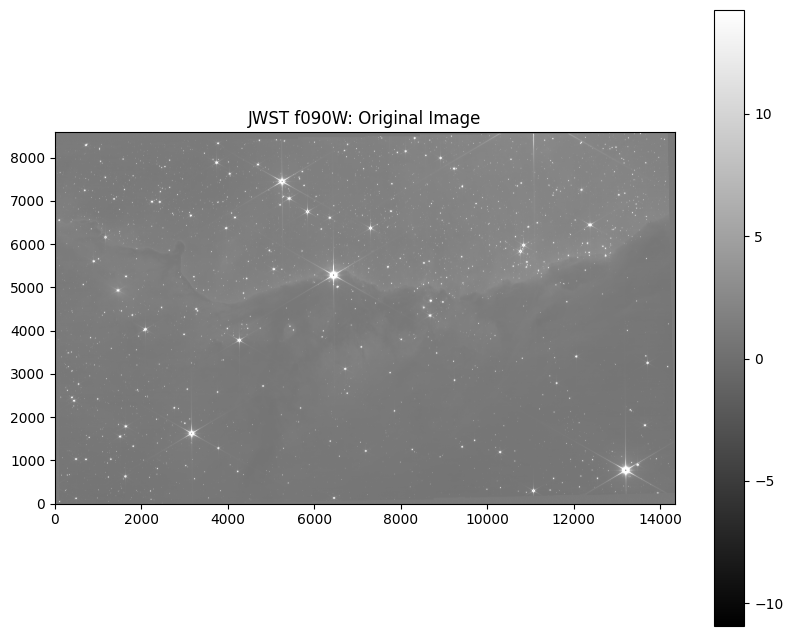

In [3]:
m, s = np.mean(data), np.std(data)
plt.imshow(data, cmap='gray', vmin=m-s, vmax=m+s, origin='lower')
plt.colorbar()
plt.title("JWST f090W: Original Image")
plt.savefig("jwst_figure1_original.png")
plt.show()

# Background estimation and subtraction

In [6]:
bkg = sep.Background(data)
data_sub = data - bkg

# Saving Background Model

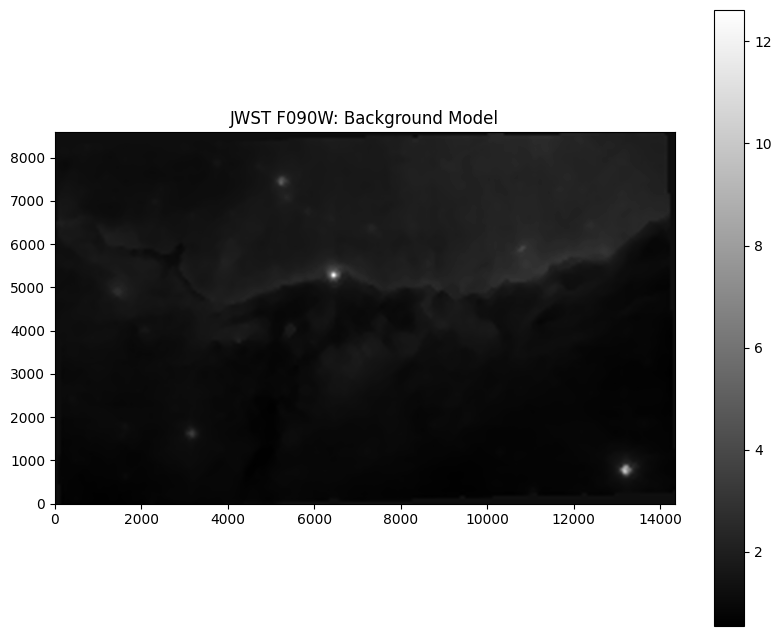

In [7]:
bkg_image = bkg.back()
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar()
plt.title("JWST F090W: Background Model")
plt.savefig("jwst_figure2_background.png")
plt.show()

# Object detection

In [8]:
sep.set_extract_pixstack(1000000)
objects = sep.extract(data_sub, thresh=5, err=bkg.globalrms)
print("Number of sources detected", len(objects))

Number of sources detected 15588


# Plot detections

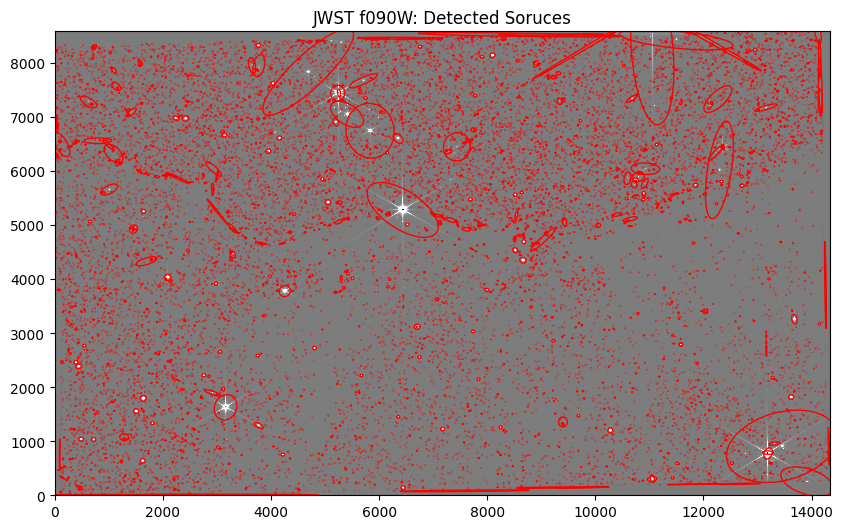

Object 0: flux = 37.16 +/- 6.11
Object 1: flux = 9.20 +/- 3.05
Object 2: flux = 12.66 +/- 3.57
Object 3: flux = 13.33 +/- 3.67
Object 4: flux = 13.91 +/- 3.74
Object 5: flux = 250.01 +/- 15.82
Object 6: flux = 36.63 +/- 6.06
Object 7: flux = 14.81 +/- 3.86
Object 8: flux = 15.70 +/- 3.98
Object 9: flux = 57.58 +/- 7.60


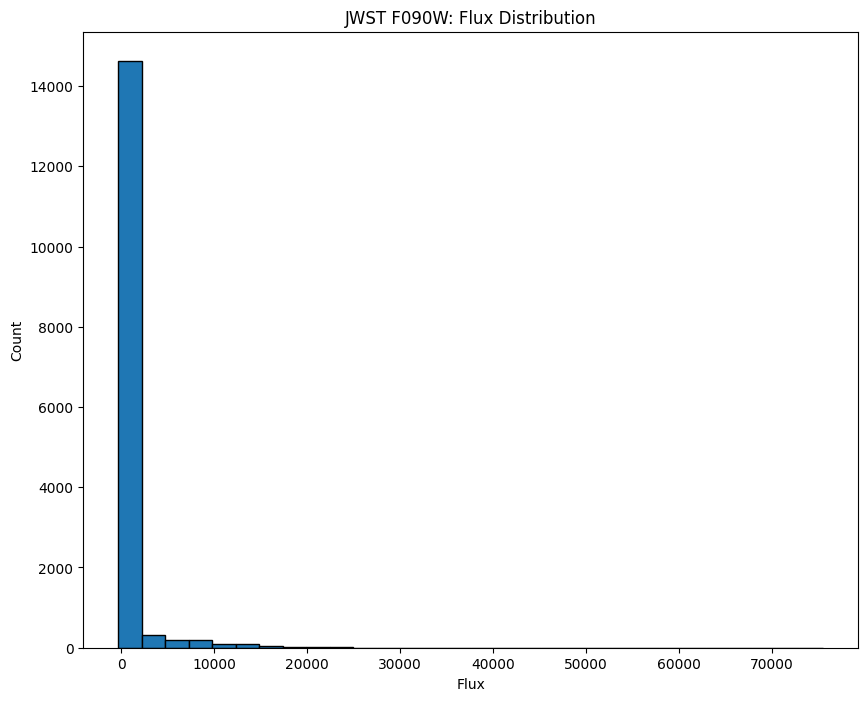

In [9]:
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
ax.imshow(data_sub, interpolation='nearest',cmap='gray', vmin=m-s, vmax=m+s, origin='lower')

for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]), width=6*objects['a'][i],height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)
ax.set_title("JWST f090W: Detected Soruces")
plt.savefig("jwst_figure3_objects.png")
plt.show()

# Aperture photometry
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                     3.0, err=bkg.globalrms, gain=1.0)

# Show sample fluxes
for i in range(min(10, len(flux))):
    print(f"Object {i}: flux = {flux[i]:.2f} +/- {fluxerr[i]:.2f}")

# Plot flux histogram
plt.hist(flux, bins=30, edgecolor='black')
plt.title("JWST F090W: Flux Distribution")
plt.xlabel("Flux")
plt.ylabel("Count")
plt.savefig("jwst_figure4_flux_histogram.png")
plt.show()

# The basic stats for flux

In [10]:
flux_mean = np.mean(flux)

flux_median = np.median(flux)
flux_std = np.std(flux)

print(f"Mean flux: {flux_mean:.2f}")
print(f"Median flux: {flux_median:.2f}")
print(f"Standard deviation: {flux_std:.2f}")

Mean flux: 643.38
Median flux: 29.40
Standard deviation: 2471.48


# Outlier info

In [11]:
max_flux_index = np.argmax(flux)
max_flux_value = flux[max_flux_index]
x_outlier = objects['x'][max_flux_index]
y_outlier = objects['y'][max_flux_index]
stds_from_mean = (max_flux_value - flux_mean) / flux_std

print(f"\nLargest outlier flux: {max_flux_value:.2f}")
print(f"Location (x, y): ({x_outlier:.2f}, {y_outlier:.2f})")
print(f"Number of standard deviations from mean: {stds_from_mean:.2f}")


Largest outlier flux: 75462.20
Location (x, y): (13194.92, 788.59)
Number of standard deviations from mean: 30.27


In [12]:
# ---------------------------------
# 0. Copy all this script into one cell, between steps 7 and 8 of your final project
#    You will need to install the "reproject" package with pip
#    This script will "reproject" all images onto the same shape using one image as a reference
# ---------------------------------

from astropy.io import fits
from astropy.wcs import WCS
from reproject import reproject_interp

# ---------------------------------
# 1. Load your reference image
#    This will define the WCS and shape for all others
# ---------------------------------
file_reference = "jw02731-o001_t017_nircam_clear-f090w_i2d.fits"
with fits.open(file_reference) as hdulist:
    # For JWST i2d images, 'SCI' is commonly the science extension
    ref_header = hdulist['SCI'].header
    ref_data = hdulist['SCI'].data

# Create a WCS object from the reference
ref_wcs = WCS(ref_header)

# This shape will be used for all reprojected images
output_shape = ref_data.shape

# ---------------------------------
# 2. Reproject the other images
# ---------------------------------
fname1 = "jw02731-o001_t017_nircam_clear-f444w_i2d.fits"
fname2 = "jw02731-o001_t017_nircam_clear-f187n_i2d.fits"
fname3 = "jw02731-o001_t017_nircam_clear-f200w_i2d.fits"
fname4 = "jw02731-o001_t017_nircam_clear-f335m_i2d.fits"
fname5 = "jw02731-o001_t017_nircam_f444w-f470n_i2d.fits"
other_filenames = [
    fname1,
    fname2,
    fname3,
    fname4,
    fname5,
]

# Reproject all other files according to the reference
for fname in other_filenames:
    with fits.open(fname) as hdulist:
        data = hdulist['SCI'].data
        header = hdulist['SCI'].header
        wcs_in = WCS(header)
    
    # Reproject this image onto the reference WCS
    # reproject_interp returns (reprojected_data, footprint)
    reprojected_data, footprint = reproject_interp(
        (data, wcs_in),
        ref_wcs,
        shape_out=output_shape,
        block_size = (1024,1024)
    )

    # Optionally, update the header to match the reference WCS
    # so that the new FITS is self-consistent
    new_header = ref_header.copy()

    # Save the new file
    out_name = fname.replace('.fits', '_reproj.fits')
    hdu = fits.PrimaryHDU(reprojected_data, header=new_header)
    hdu.writeto(out_name, overwrite=True)
    print(f"Reprojected {fname} -> {out_name}")

Set DATE-AVG to '2022-06-03T12:17:28.687' from MJD-AVG.
Set DATE-END to '2022-06-03T14:54:43.830' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.567170 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654335564.228 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T12:45:26.346' from MJD-AVG.
Set DATE-END to '2022-06-03T15:22:38.772' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.574431 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654445751.087 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


Reprojected jw02731-o001_t017_nircam_clear-f444w_i2d.fits -> jw02731-o001_t017_nircam_clear-f444w_i2d_reproj.fits


Set DATE-AVG to '2022-06-03T11:43:37.007' from MJD-AVG.
Set DATE-END to '2022-06-03T14:26:16.631' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.557313 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654186065.609 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.567170 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654335564.228 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


Reprojected jw02731-o001_t017_nircam_clear-f187n_i2d.fits -> jw02731-o001_t017_nircam_clear-f187n_i2d_reproj.fits


Set DATE-AVG to '2022-06-03T12:45:26.326' from MJD-AVG.
Set DATE-END to '2022-06-03T15:22:38.772' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.574431 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654445751.087 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.567170 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654335564.228 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


Reprojected jw02731-o001_t017_nircam_clear-f200w_i2d.fits -> jw02731-o001_t017_nircam_clear-f200w_i2d_reproj.fits


Set DATE-AVG to '2022-06-03T12:17:28.706' from MJD-AVG.
Set DATE-END to '2022-06-03T14:54:43.830' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.567170 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654335564.228 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


Reprojected jw02731-o001_t017_nircam_clear-f335m_i2d.fits -> jw02731-o001_t017_nircam_clear-f335m_i2d_reproj.fits


Set DATE-AVG to '2022-06-03T11:43:37.025' from MJD-AVG.
Set DATE-END to '2022-06-03T14:26:16.695' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.557313 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654186065.609 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.567170 from OBSGEO-[XYZ].
Set OBSGEO-H to 1654335564.228 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


Reprojected jw02731-o001_t017_nircam_f444w-f470n_i2d.fits -> jw02731-o001_t017_nircam_f444w-f470n_i2d_reproj.fits


# Loading reprojected images


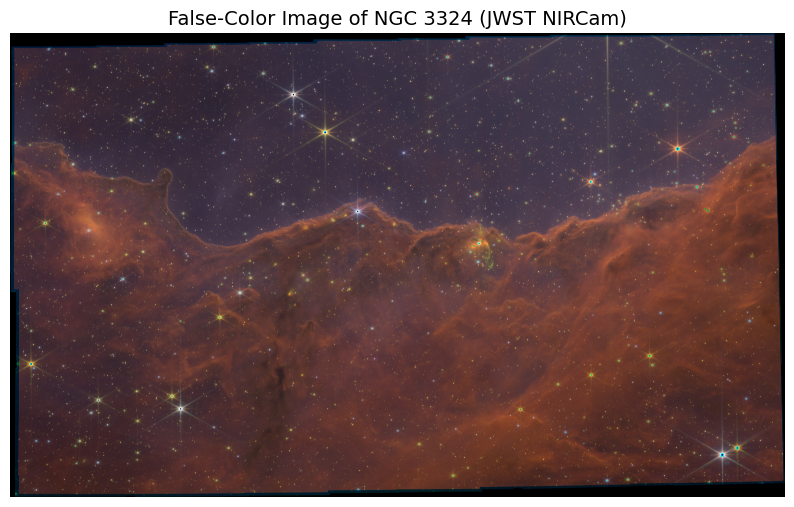

In [17]:

# Function to load and normalize FITS image using extension index
def load_and_normalize(filename):
    with fits.open(filename) as hdul:
        # Try 'SCI' extension first, or go to first HDU with data
        if 'SCI' in hdul:
            data = hdul['SCI'].data
        else:
            for hdu in hdul:
                if hdu.data is not None:
                    data = hdu.data
                    break
    data = np.nan_to_num(data)
    data = np.clip(data, 0, None) 
    data = np.log10(data + 1)  # add 1 to avoid log(0)
    data -= np.min(data)
    if np.max(data) > 0:
        data /= np.max(data)
    return data
# Load and normalize all 6 reprojected images
f090w = load_and_normalize("jw02731-o001_t017_nircam_clear-f090w_i2d.fits")                  # Blue
f187n = load_and_normalize("jw02731-o001_t017_nircam_clear-f187n_i2d_reproj.fits")           # Cyan
f200w = load_and_normalize("jw02731-o001_t017_nircam_clear-f200w_i2d_reproj.fits")           # Green
f335m = load_and_normalize("jw02731-o001_t017_nircam_clear-f335m_i2d_reproj.fits")           # Orange
f444w = load_and_normalize("jw02731-o001_t017_nircam_clear-f444w_i2d_reproj.fits")           # Red
f470n = load_and_normalize("jw02731-o001_t017_nircam_f444w-f470n_i2d_reproj.fits")           # Yellow

# Combining into RGB image
r = np.clip(f444w + 0.5 * f335m, 0, 1)
g = np.clip(f200w + 0.5 * f470n, 0, 1)
b = np.clip(f090w + 0.5 * f187n, 0, 1)

rgb = np.stack([r, g, b], axis=-1)

# Display and save
plt.figure(figsize=(10, 10))
plt.imshow(rgb, origin='lower')
plt.axis('off')
plt.title("False-Color Image of NGC 3324 (JWST NIRCam)", fontsize=14)
plt.savefig("ngc3324_false_color_all_filters.png", dpi=300, bbox_inches='tight')
plt.show()
